# New Dataset → Synthetic Night Training → Real Night Testing

**Goal:** Use the 665-image New Dataset (Pascal VOC XML, daytime road images) to train a YOLO11 pothole detector on **synthetic night images** and evaluate it on a **real night-time test set**.

| Step | What happens |
|---|---|
| 1 | Install dependencies |
| 2 | Config & helpers |
| 3 | Convert Pascal VOC XML → YOLO format |
| 4 | Leak-free train / val / test split (70 / 15 / 15) |
| 5 | Day → Night transformation (visualise) |
| 6 | Write synthetic-night YOLO dataset to disk |
| 7 | Prepare real-night test set |
| 8 | Train YOLO11m on synthetic night images |
| 9 | Evaluate on real-night test set |
| 10 | Qualitative results & download |

## Step 1 — Install Dependencies

In [1]:
!pip install -q -U ultralytics
print('Done.')

Done.


## Step 2 — Config & Helpers

In [25]:
import os, re, json, glob, shutil, random, time, yaml, warnings, gc, zipfile
from pathlib import Path
from collections import Counter, defaultdict

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from tqdm.auto import tqdm
from IPython.display import display, FileLink

import torch
from ultralytics import YOLO

warnings.filterwarnings('ignore')

# ─────────────────────────────────────────────────────────────
#  ZIP EXTRACTION & PATHS
# ─────────────────────────────────────────────────────────────
# Extract datasets uploaded in /content using system unzip for maximum reliability
for zip_name, dest_name in [
    ('New Dataset.zip', 'new-dataset-potholes'),
    ('night_plothole.zip', 'night-potholes-yolov8-format'),
    ('archive.zip', 'night-potholes-yolov8-format')
]:
    zip_path = Path(f'/content/{zip_name}')
    dest_path = Path(f'/content/{dest_name}')
    if zip_path.exists():
        # Clean up existing directory to avoid corrupted states
        if dest_path.exists() and zip_name == 'night_plothole.zip':
            print(f"Cleaning up old directory {dest_path} for clean extraction...")
            shutil.rmtree(dest_path)

        if not dest_path.exists():
            print(f"Extracting {zip_name} to {dest_path} via system unzip...")
            dest_path.mkdir(parents=True, exist_ok=True)
            # Use system unzip which handles ZIP structure anomalies much better than python zipfile
            os.system(f'unzip -q -o "{zip_path}" -d "{dest_path}"')

# New Dataset: flat VOC layout
NEW_DATA_DIR = Path('/content/new-dataset-potholes')

# Real night dataset (YOLO format)
REAL_DIR = Path('/content/night-potholes-yolov8-format')
REAL_POTHOLE_CLASS_ID = 1   # pothole class id in the real set

# Working directory (Colab: /content/working)
WORK = Path('/content/working')

# ─────────────────────────────────────────────────────────────
#  HYPERPARAMETERS
# ─────────────────────────────────────────────────────────────
SPLIT_FRACS  = (0.70, 0.15, 0.15)   # train / val / test
HASH_THR     = 6                     # Hamming distance for near-dup detection
SEED         = 42

MODEL_WEIGHTS = 'yolo11m.pt'         # COCO-pretrained init
IMG_SIZE      = 640
EPOCHS        = 100
BATCH_SIZE    = 16                   # reduce to 8 if OOM
PATIENCE      = 15
DEVICE        = 0 if torch.cuda.is_available() else 'cpu'

# Night-simulation parameters
NIGHT_DARK_FACTOR      = 0.35
NIGHT_NOISE_STD        = 8
NIGHT_VIGNETTE         = 0.45
NIGHT_GAMMA            = 2.2
NIGHT_COLOR_SHIFT_BGR  = (-10, -5, +5)   # slight warm cast (road lighting)

# Output folders
OUT_DIR    = WORK / 'synthetic_night_dataset'
FIGS_DIR   = WORK / 'figures'
for d in (OUT_DIR, FIGS_DIR): d.mkdir(parents=True, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f'Device: {DEVICE} | PyTorch {torch.__version__}')
print(f'New Dataset : {NEW_DATA_DIR}')
print(f'Real night  : {REAL_DIR}')
print(f'Output dir  : {OUT_DIR}')

Cleaning up old directory /content/night-potholes-yolov8-format for clean extraction...
Extracting night_plothole.zip to /content/night-potholes-yolov8-format via system unzip...
Device: 0 | PyTorch 2.14.1+cu130
New Dataset : /content/new-dataset-potholes
Real night  : /content/night-potholes-yolov8-format
Output dir  : /content/working/synthetic_night_dataset


In [26]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

# ── image / label I/O ───────────────────────────────────────
def list_images(d):
    return sorted(p for p in Path(d).iterdir() if p.suffix.lower() in IMAGE_EXTS)

def label_path_for(img_path):
    p = Path(img_path)
    return p.parent.parent / 'labels' / (p.stem + '.txt')

def read_yolo_labels(path):
    rows = []
    path = Path(path)
    if path.exists():
        for line in path.read_text().splitlines():
            parts = line.split()
            if len(parts) == 5:
                rows.append([float(x) for x in parts])
    return np.array(rows, dtype=np.float32).reshape(-1, 5)

def write_yolo_label(path, boxes):
    """boxes: (N,5) array [cls xc yc w h] all normalised."""
    with open(path, 'w') as f:
        for row in boxes:
            f.write(f'0 {row[1]:.6f} {row[2]:.6f} {row[3]:.6f} {row[4]:.6f}\n')

def draw_boxes(img_bgr, lab, color=(0, 220, 0), thick=2):
    h, w = img_bgr.shape[:2]
    for _, xc, yc, bw, bh in lab:
        x1 = int((xc - bw/2)*w); y1 = int((yc - bh/2)*h)
        x2 = int((xc + bw/2)*w); y2 = int((yc + bh/2)*h)
        cv2.rectangle(img_bgr, (x1, y1), (x2, y2), color, thick)
    return img_bgr

def mean_gray(path):
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return float(g.mean()) if g is not None else 0.0

def savefig(name):
    plt.savefig(FIGS_DIR / name, dpi=150, bbox_inches='tight')

# ── perceptual hash ──────────────────────────────────────────
def dhash(path):
    g = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if g is None: return np.zeros(64, bool), np.zeros(64, bool)
    g  = cv2.resize(g, (9, 8), interpolation=cv2.INTER_AREA)
    h  = (g[:, 1:] > g[:, :-1]).ravel()
    hf = (g[:, ::-1][:, 1:] > g[:, ::-1][:, :-1]).ravel()
    return h, hf

def compute_hashes(paths):
    pairs = [dhash(p) for p in paths]
    H  = np.array([p[0] for p in pairs], dtype=bool)
    Hf = np.array([p[1] for p in pairs], dtype=bool)
    return H, Hf

def min_hamming_to_set(H_query, H_ref, Hf_ref, chunk=128):
    best = np.full(len(H_query), 64)
    for s in range(0, len(H_query), chunk):
        a = H_query[s:s+chunk, None, :]
        d = np.minimum((a != H_ref[None]).sum(2),
                       (a != Hf_ref[None]).sum(2))
        best[s:s+chunk] = d.min(1)
    return best

print('Helpers ready.')

Helpers ready.


## Step 3 — Convert Pascal VOC XML → YOLO Format

Parses every `.xml` in `annotations/`, converts absolute pixel bounding boxes to YOLO normalised format, keeps only `pothole` objects (remapped to class 0).

In [27]:
import xml.etree.ElementTree as ET

# Dynamically find the annotations and images directories in case they are nested inside the extracted folder
ANNO_DIR = None
IMG_SRC = None

# Search recursively for directories named 'annotations' and 'images'
for p in NEW_DATA_DIR.rglob('*'):
    if p.is_dir() and p.name.lower() == 'annotations':
        ANNO_DIR = p
    elif p.is_dir() and p.name.lower() == 'images':
        IMG_SRC = p

# Fallback to flat NEW_DATA_DIR if specific subdirectories aren't found
if ANNO_DIR is None:
    ANNO_DIR = NEW_DATA_DIR / 'annotations'
if IMG_SRC is None:
    IMG_SRC = NEW_DATA_DIR / 'images'

print(f"Resolved Annotations Directory: {ANNO_DIR}")
print(f"Resolved Images Directory: {IMG_SRC}")

def parse_voc(xml_path):
    """Returns (img_filename, [(xc,yc,w,h) normalised, ...]) or None if no pothole."""
    try:
        root = ET.parse(xml_path).getroot()
        sz   = root.find('size')
        if sz is None or root.find('object') is None:
            return None
        W, H = float(sz.find('width').text), float(sz.find('height').text)
        if W == 0 or H == 0:
            return None
        boxes = []
        for obj in root.findall('object'):
            name_node = obj.find('name')
            if name_node is None or name_node.text.strip().lower() != 'pothole':
                continue
            bb = obj.find('bndbox')
            if bb is None: continue
            xmin = max(0.0, float(bb.find('xmin').text))
            ymin = max(0.0, float(bb.find('ymin').text))
            xmax = min(W,   float(bb.find('xmax').text))
            ymax = min(H,   float(bb.find('ymax').text))
            if xmax <= xmin or ymax <= ymin: continue
            boxes.append(((xmin+xmax)/(2*W), (ymin+ymax)/(2*H),
                          (xmax-xmin)/W,     (ymax-ymin)/H))
        img_file_node = root.find('filename')
        img_file = img_file_node.text.strip() if img_file_node is not None else (xml_path.stem + '.jpg')
        return img_file, boxes
    except Exception as e:
        return None

all_items = []   # list of dicts: {img, boxes}
skipped_no_img, skipped_no_box = 0, 0

if ANNO_DIR.exists():
    for xml_path in tqdm(sorted(ANNO_DIR.glob('**/*.xml')), desc='Parsing XML'):
        parsed = parse_voc(xml_path)
        if parsed is None:
            skipped_no_box += 1; continue
        img_file, boxes = parsed
        if not boxes:
            skipped_no_box += 1; continue

        # Find the actual image file corresponding to this XML
        img_path = None
        for ext in IMAGE_EXTS:
            c = IMG_SRC / (xml_path.stem + ext)
            if c.exists(): img_path = c; break
        if img_path is None:
            c = IMG_SRC / img_file
            if c.exists(): img_path = c
        if img_path is None:
            skipped_no_img += 1; continue

        all_items.append({'img': img_path,
                          'boxes': np.array([[0]+list(b) for b in boxes],
                                            dtype=np.float32)})

print(f'Total XML files found  : {len(list(ANNO_DIR.glob("**/*.xml")))}')
print(f'Usable items           : {len(all_items)}')
print(f'Skipped (no img)       : {skipped_no_img}')
print(f'Skipped (no box)       : {skipped_no_box}')
print(f'Total boxes            : {sum(len(it["boxes"]) for it in all_items)}')


Resolved Annotations Directory: /content/new-dataset-potholes/New Dataset/annotations
Resolved Images Directory: /content/new-dataset-potholes/New Dataset/images


Parsing XML:   0%|          | 0/665 [00:00<?, ?it/s]

Total XML files found  : 665
Usable items           : 665
Skipped (no img)       : 0
Skipped (no box)       : 0
Total boxes            : 1739


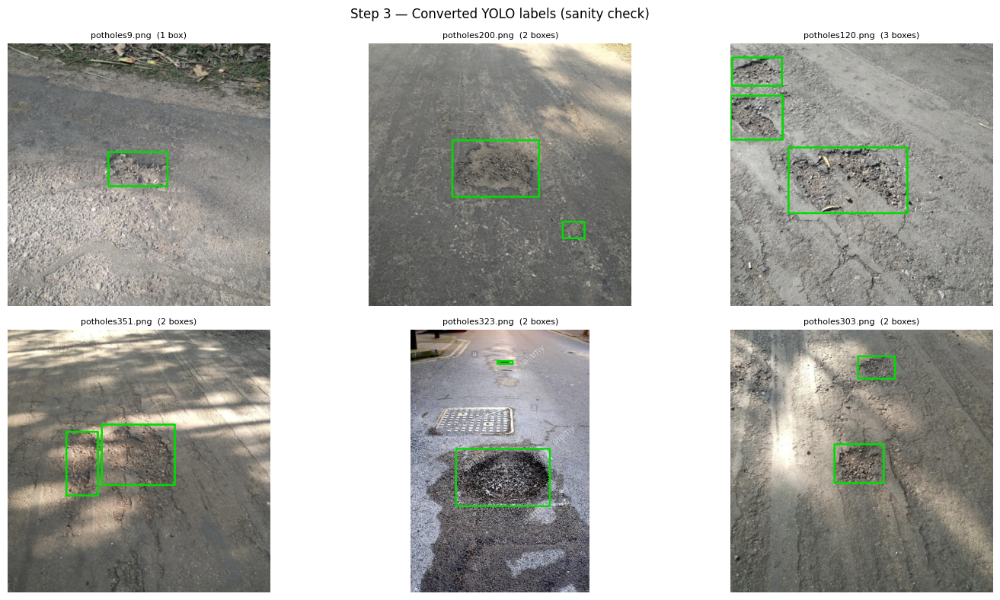

In [28]:
# Visual sanity-check: 6 converted images with boxes
show = random.Random(SEED).sample(all_items, min(6, len(all_items)))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, it in zip(axes.flat, show):
    img = cv2.imread(str(it['img']))
    img = draw_boxes(img.copy(), it['boxes'])
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{it['img'].name}  ({len(it['boxes'])} box{'es' if len(it['boxes'])>1 else ''})",
                 fontsize=8)
    ax.axis('off')
plt.suptitle('Step 3 — Converted YOLO labels (sanity check)', fontsize=12)
plt.tight_layout(); savefig('01_conversion_check.png'); plt.show()

## Step 4 — Leak-Free Train / Val / Test Split

Images are grouped by **perceptual hash** (Hamming distance ≤ `HASH_THR`, including mirrors). Whole groups are assigned to one split so no near-duplicate can straddle train and test. Split: 70 / 15 / 15.

In [29]:
print('Computing perceptual hashes…')
paths_all = [it['img'] for it in all_items]
H, Hf = compute_hashes(paths_all)
n = len(all_items)

# Union-Find grouping
parent = list(range(n))
def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]; x = parent[x]
    return x

for i in range(n):
    dm = np.minimum((H[i][None] != H).sum(1),
                    (H[i][None] != Hf).sum(1))
    for j in np.where(dm <= HASH_THR)[0]:
        ri, rj = find(i), find(int(j))
        if ri != rj: parent[ri] = rj

groups = defaultdict(list)
for i in range(n): groups[find(i)].append(i)
glist = list(groups.values())
random.Random(SEED).shuffle(glist)

# Greedy fill to hit target proportions
target = [f*n for f in SPLIT_FRACS]
cur = [0, 0, 0]; buckets = [[], [], []]
for g in sorted(glist, key=len, reverse=True):
    k = int(np.argmax([target[s]-cur[s] for s in range(3)]))
    buckets[k] += g; cur[k] += len(g)

SPLITS = {sp: [all_items[i] for i in idx]
           for sp, idx in zip(['train','val','test'], buckets)}

for sp, its in SPLITS.items():
    print(f'  {sp:5s}: {len(its):4d} images, '
          f'{sum(len(it["boxes"]) for it in its)} boxes')

# Leak audit
Htr, Htr_f = compute_hashes([it['img'] for it in SPLITS['train']])
for sp in ('val', 'test'):
    Hs, _ = compute_hashes([it['img'] for it in SPLITS[sp]])
    if len(Hs):
        d = min_hamming_to_set(Hs, Htr, Htr_f)
        print(f'  Leak audit {sp}: {int((d<=HASH_THR).sum())} near-dups in train (should be 0)')

Computing perceptual hashes…
  train:  465 images, 1214 boxes
  val  :  100 images, 288 boxes
  test :  100 images, 237 boxes
  Leak audit val: 0 near-dups in train (should be 0)
  Leak audit test: 0 near-dups in train (should be 0)


## Step 5 — Day → Night Transformation (Visualise)

The same scene is first darkened with a gamma curve, then a warm colour cast (road-lamp hue) is added, Gaussian sensor noise is overlaid, and finally a radial vignette simulates headlight fall-off. Labels are **unchanged** — only pixels change.

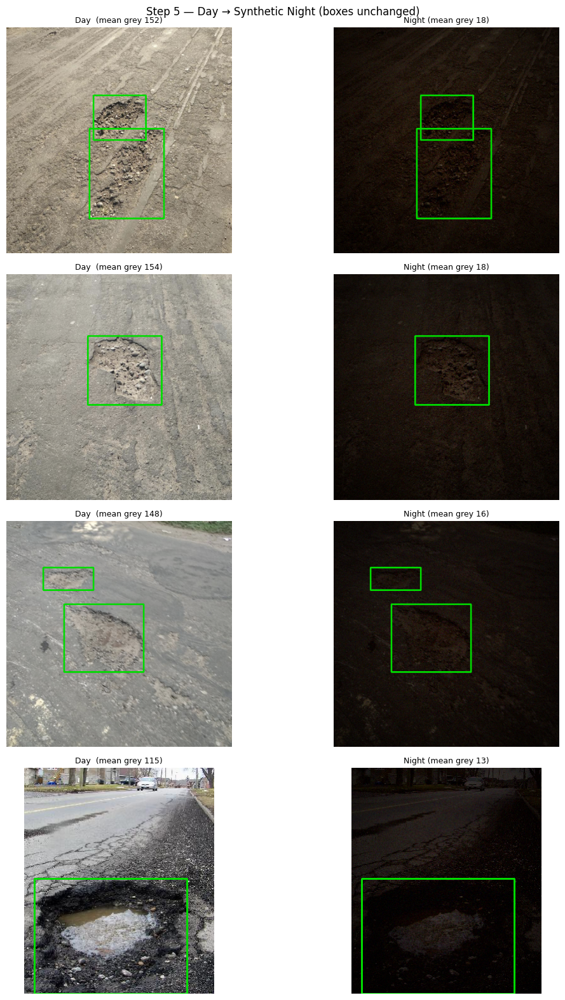

In [30]:
def simulate_night(img_bgr, seed=None):
    """
    Daytime BGR → synthetic night BGR.
    1. Gamma darkening  (gamma > 1 darkens)
    2. Warm colour cast (road sodium/LED lamps)
    3. Gaussian sensor noise
    4. Radial vignette  (headlight fall-off)
    """
    rng = np.random.default_rng(seed)
    img = img_bgr.astype(np.float32) / 255.0

    # 1. Gamma + overall brightness reduction
    img = np.power(np.clip(img, 1e-6, 1.0), NIGHT_GAMMA) * NIGHT_DARK_FACTOR

    # 2. Warm colour shift  (B-=10, G-=5, R+=5  in [0,255] scale)
    for c, shift in enumerate(NIGHT_COLOR_SHIFT_BGR):
        img[:,:,c] = np.clip(img[:,:,c] + shift/255.0, 0, 1)

    # 3. Gaussian noise (simulates high-ISO sensor noise)
    img = np.clip(img + rng.normal(0, NIGHT_NOISE_STD/255.0,
                                    img.shape).astype(np.float32), 0, 1)

    # 4. Vignette
    h, w = img.shape[:2]
    Y, X = np.ogrid[:h, :w]
    dist  = np.sqrt(((X - w/2)/(w/2))**2 + ((Y - h/2)/(h/2))**2)
    vig   = np.clip(1.0 - NIGHT_VIGNETTE * dist, 0, 1).astype(np.float32)
    img  *= vig[:,:,None]

    return (np.clip(img, 0, 1) * 255).astype(np.uint8)

# ── Demo grid: 4 images, Day | Night ────────────────────────
demo = random.Random(SEED).sample(SPLITS['train'], min(4, len(SPLITS['train'])))
fig, axes = plt.subplots(4, 2, figsize=(12, 16))
for i, it in enumerate(demo):
    img_day = cv2.imread(str(it['img']))
    img_ngt = simulate_night(img_day, seed=SEED+i)
    for j, (title, im) in enumerate([
        (f"Day  (mean grey {cv2.cvtColor(img_day,cv2.COLOR_BGR2GRAY).mean():.0f})",  img_day),
        (f"Night (mean grey {cv2.cvtColor(img_ngt,cv2.COLOR_BGR2GRAY).mean():.0f})", img_ngt)
    ]):
        ax = axes[i][j]
        ax.imshow(cv2.cvtColor(draw_boxes(im.copy(), it['boxes']),
                               cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=9); ax.axis('off')
plt.suptitle('Step 5 — Day → Synthetic Night (boxes unchanged)', fontsize=12)
plt.tight_layout(); savefig('02_night_transform_demo.png'); plt.show()

## Step 6 — Write Synthetic-Night YOLO Dataset

For every split (train / val / test) we apply `simulate_night()` to every day image and write:
- `synthetic_night_dataset/<split>/images/<stem>.jpg`
- `synthetic_night_dataset/<split>/labels/<stem>.txt`
- `synthetic_night_dataset/data.yaml`

In [31]:
def write_split(split_name, items, out_root, apply_night=True):
    idir = out_root / split_name / 'images'
    ldir = out_root / split_name / 'labels'
    idir.mkdir(parents=True, exist_ok=True)
    ldir.mkdir(parents=True, exist_ok=True)

    for idx, it in enumerate(tqdm(items, desc=f'Writing {split_name}', leave=False)):
        img = cv2.imread(str(it['img']))
        if img is None:
            print(f'Warning: could not read {it["img"]}, skipping'); continue

        if apply_night:
            img = simulate_night(img, seed=SEED + idx)

        # Save as JPEG q95 (standardise encoding across all splits)
        stem = f'{split_name}_{idx:05d}'
        cv2.imwrite(str(idir / f'{stem}.jpg'), img,
                    [cv2.IMWRITE_JPEG_QUALITY, 95])
        write_yolo_label(ldir / f'{stem}.txt', it['boxes'])

    return len(list(idir.iterdir()))

# Train and val: apply night transformation
# Test split is left as-is so we can see detection on the synthetic set too
n_tr = write_split('train', SPLITS['train'], OUT_DIR, apply_night=True)
n_va = write_split('val',   SPLITS['val'],   OUT_DIR, apply_night=True)
n_te = write_split('test',  SPLITS['test'],  OUT_DIR, apply_night=True)

# Write data.yaml
data_yaml_path = OUT_DIR / 'data.yaml'
with open(data_yaml_path, 'w') as f:
    yaml.dump({
        'path':  str(OUT_DIR),
        'train': 'train/images',
        'val':   'val/images',
        'test':  'test/images',
        'nc':    1,
        'names': {0: 'pothole'}
    }, f, sort_keys=False)

print(f'Dataset written to: {OUT_DIR}')
print(f'  train: {n_tr} images')
print(f'  val:   {n_va} images')
print(f'  test:  {n_te} images')
print(f'  data.yaml: {data_yaml_path}')

# Confirm brightness is now dark (night-like)
samples = random.Random(SEED).sample(list((OUT_DIR/'train'/'images').iterdir()), min(30, n_tr))
br = [mean_gray(p) for p in samples]
print(f'  Mean brightness (train, sample of {len(samples)}): {np.mean(br):.1f} '
      f'(original day ~{np.mean([mean_gray(it["img"]) for it in SPLITS["train"][:30]]):.1f})')

Writing train:   0%|          | 0/465 [00:00<?, ?it/s]

Writing val:   0%|          | 0/100 [00:00<?, ?it/s]

Writing test:   0%|          | 0/100 [00:00<?, ?it/s]

Dataset written to: /content/working/synthetic_night_dataset
  train: 465 images
  val:   100 images
  test:  100 images
  data.yaml: /content/working/synthetic_night_dataset/data.yaml
  Mean brightness (train, sample of 30): 13.8 (original day ~125.4)


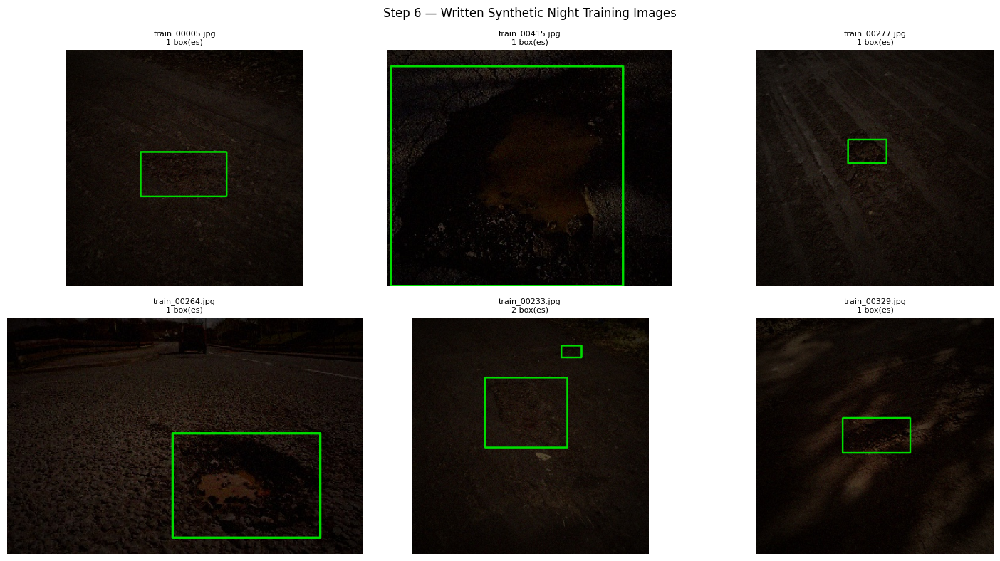

In [32]:
# Quick visual check of written dataset
train_imgs = list((OUT_DIR / 'train' / 'images').iterdir())
show_paths = random.Random(SEED+1).sample(train_imgs, min(6, len(train_imgs)))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, p in zip(axes.flat, show_paths):
    img = cv2.imread(str(p))
    lab = read_yolo_labels(label_path_for(p))
    ax.imshow(cv2.cvtColor(draw_boxes(img, lab), cv2.COLOR_BGR2RGB))
    ax.set_title(f'{p.name}\n{len(lab)} box(es)', fontsize=8)
    ax.axis('off')
plt.suptitle('Step 6 — Written Synthetic Night Training Images', fontsize=12)
plt.tight_layout(); savefig('03_written_dataset_check.png'); plt.show()

## Step 7 — Prepare Real-Night Test Set

Load the real night dataset, keep only pothole-class boxes (remap to class 0), apply the same hash-based leak-free split, and collect the **test** split for final evaluation.

In [33]:
def find_all_images_and_labels(root_dir):
    root_dir = Path(root_dir)

    # Debug print the directory structure to see where the files actually went
    all_paths = list(root_dir.rglob('*'))
    print(f"Total items found in {root_dir}: {len(all_paths)}")
    # Print first 15 files/dirs to understand structure
    for p in all_paths[:15]:
        print(f" - {p.relative_to(root_dir)}")

    # Find all image paths recursively, ignoring extension case
    extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.webp', '*.JPG', '*.JPEG', '*.PNG', '*.BMP', '*.WEBP']
    all_imgs = []
    for ext in extensions:
        all_imgs.extend(list(root_dir.rglob(ext)))
    all_imgs = sorted(list(set(all_imgs)))

    # Map image stem to the image path
    img_map = {img.stem: img for img in all_imgs}

    # Find all .txt files recursively
    all_labels = sorted(list(root_dir.rglob('*.txt')))

    items = []
    # Match them by file stem
    for lp in all_labels:
        if lp.stem == 'classes':
            continue
        if lp.stem in img_map:
            img_p = img_map[lp.stem]
            lab = read_yolo_labels(lp)
            if len(lab) == 0:
                continue
            # Map any class present to class 0 (since it's a single class dataset usually)
            lab_keep = lab.copy()
            lab_keep[:, 0] = 0
            items.append({'path': img_p, 'lab': lab_keep})

    return items

# Handle possible nested subdirectories inside extracted night-potholes-yolov8-format folder
if REAL_DIR.exists():
    subdirs = [p for p in REAL_DIR.iterdir() if p.is_dir()]
    if len(subdirs) == 1 and (subdirs[0] / 'images').exists() or not list(REAL_DIR.glob('*.txt')):
        # Check if there's an obvious nested directory
        test_sub = REAL_DIR / 'night-potholes-yolov8-format'
        if test_sub.exists():
            REAL_DIR = test_sub
        elif len(subdirs) == 1:
            REAL_DIR = subdirs[0]

real_items = find_all_images_and_labels(REAL_DIR)
print('Resolved Real night root:', REAL_DIR)
print(f'Real night images with potholes: {len(real_items)}')
print(f'Total real boxes: {sum(len(r["lab"]) for r in real_items)}')

# Hash-based split
nr = len(real_items)
if nr > 0:
    H_r, Hf_r = compute_hashes([r["path"] for r in real_items])
    parent_r = list(range(nr))
    def find_r(x):
        while parent_r[x] != x:
            parent_r[x] = parent_r[parent_r[x]]; x = parent_r[x]
        return x
    for i in range(nr):
        dm = np.minimum((H_r[i][None] != H_r).sum(1),
                        (H_r[i][None] != Hf_r).sum(1))
        for j in np.where(dm <= HASH_THR)[0]:
            ri, rj = find_r(i), find_r(int(j))
            if ri != rj: parent_r[ri] = rj
    grps_r = defaultdict(list)
    for i in range(nr): grps_r[find_r(i)].append(i)
    glist_r = list(grps_r.values())
    random.Random(SEED).shuffle(glist_r)
    tgt_r = [f*nr for f in SPLIT_FRACS]; cur_r=[0,0,0]; bkts_r=[[],[],[]]
    for g in sorted(glist_r, key=len, reverse=True):
        k = int(np.argmax([tgt_r[s]-cur_r[s] for s in range(3)]))
        bkts_r[k]+=g; cur_r[k]+=len(g)
    real_split = {sp: [real_items[i] for i in idx]
                   for sp, idx in zip(["train","val","test"], bkts_r)}
else:
    real_split = {"train": [], "val": [], "test": []}

for sp, v in real_split.items():
    print(f'  real {sp:5s}: {len(v):4d} images')

# Write real test images for evaluation
REAL_TEST_DIR = WORK / 'real_test'
REAL_TEST_DIR.mkdir(parents=True, exist_ok=True)
(REAL_TEST_DIR/'images').mkdir(parents=True, exist_ok=True)
(REAL_TEST_DIR/'labels').mkdir(parents=True, exist_ok=True)
for idx, r in enumerate(real_split['test']):
    stem = f'real_test_{idx:05d}'
    shutil.copy2(r['path'], REAL_TEST_DIR/'images'/(stem + r['path'].suffix))
    write_yolo_label(REAL_TEST_DIR/'labels'/(stem+'.txt'), r['lab'])
print(f'Real test images written: {len(real_split["test"])}')

# Write real val set so YOLO can monitor val mAP during training
REAL_VAL_DIR = WORK / 'real_val'
REAL_VAL_DIR.mkdir(parents=True, exist_ok=True)
(REAL_VAL_DIR/'images').mkdir(parents=True, exist_ok=True)
(REAL_VAL_DIR/'labels').mkdir(parents=True, exist_ok=True)
for idx, r in enumerate(real_split['val']):
    stem = f'real_val_{idx:05d}'
    shutil.copy2(r['path'], REAL_VAL_DIR/'images'/(stem + r['path'].suffix))
    write_yolo_label(REAL_VAL_DIR/'labels'/(stem+'.txt'), r['lab'])

Total items found in /content/night-potholes-yolov8-format/train: 2892
 - labels
 - images
 - labels/107_jpg.rf.42c9f47bbec3e62313e4432ba027f408.txt
 - labels/143_jpg.rf.e1975349fb20eaf4351a8f0db1e08a5f.txt
 - labels/121_jpg.rf.ec7c11776dc45628350f598744df362a.txt
 - labels/99_jpg.rf.05779f4fe35cf54354b552048ede3900.txt
 - labels/83_jpg.rf.db27881069550f3b6d5d1dbf6284c7ef.txt
 - labels/29_jpg.rf.afe43ae80733c64ad338315a15b099e4.txt
 - labels/97_jpg.rf.34263ab14506639770bf6385171b5704.txt
 - labels/264_jpg.rf.5a408485dc6c94895f0952b107d45b18.txt
 - labels/169_jpg.rf.aedbf189e88618df619c0bfcebcd3098.txt
 - labels/frame_0049_jpg.rf.0566afc5d9858b5cc88d15c9296d1404.txt
 - labels/132_jpg.rf.b8ff82bd0a710e77a9beb0548148e476.txt
 - labels/176_jpg.rf.788c853e4130143a5b36a9dbb90554c9.txt
 - labels/163_jpg.rf.5178464927a3918af9da3cb0a066e32e.txt
Resolved Real night root: /content/night-potholes-yolov8-format/train
Real night images with potholes: 1445
Total real boxes: 3385
  real train: 1011 im

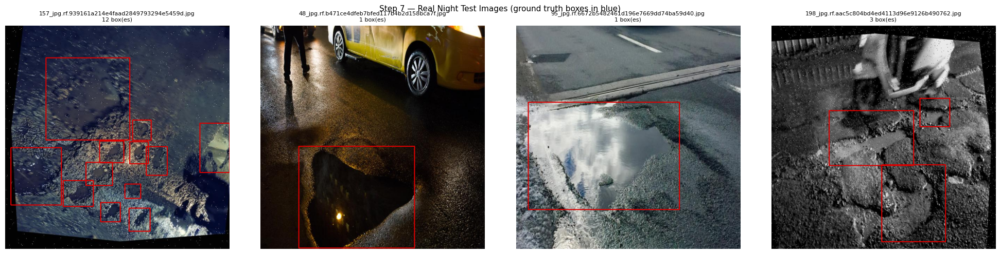

In [34]:
# Preview 4 real night test images
show_real = random.Random(SEED).sample(real_split['test'], min(4, len(real_split['test'])))
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, r in zip(axes, show_real):
    img = cv2.imread(str(r['path']))
    img = draw_boxes(img.copy(), r['lab'], color=(0,0,220))
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{r['path'].name}\n{len(r['lab'])} box(es)", fontsize=8)
    ax.axis('off')
plt.suptitle('Step 7 — Real Night Test Images (ground truth boxes in blue)', fontsize=11)
plt.tight_layout(); savefig('04_real_night_preview.png'); plt.show()

## Step 8 — Train YOLO11m on Synthetic Night Images

We train a COCO-pretrained YOLO11m using the synthetic night dataset. The validation set is also synthetic night (since at inference time on a production system we wouldn't have real night labels). After training completes we additionally run `val()` on the **real night val** set to track cross-domain performance.

In [35]:
PROJECT_DIR = WORK / 'runs'
RUN_NAME    = 'yolo11m_synthetic_night'

model = YOLO(MODEL_WEIGHTS)

print(f'Training {MODEL_WEIGHTS} on synthetic night images for {EPOCHS} epochs...')
print(f'Train: {n_tr} imgs | Val: {n_va} imgs | imgsz={IMG_SIZE} | batch={BATCH_SIZE}')

results = model.train(
    data=str(data_yaml_path),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    device=DEVICE,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    optimizer='AdamW',
    cos_lr=True,
    lr0=0.001,
    lrf=0.01,
    warmup_epochs=3,
    close_mosaic=10,
    patience=PATIENCE,
    mosaic=1.0,
    mixup=0.05,
    scale=0.5,
    fliplr=0.5,
    flipud=0.0,
    degrees=5.0,
    hsv_h=0.01,
    hsv_s=0.4,
    hsv_v=0.3,          # mild HSV — night images are already dark
    amp=True,
    seed=SEED,
    save=True,
    save_period=10,
    plots=True,
    verbose=True,
    exist_ok=True,
)

BEST_PT = PROJECT_DIR / RUN_NAME / 'weights' / 'best.pt'
print(f'\nTraining done. Best checkpoint: {BEST_PT}')

Training yolo11m.pt on synthetic night images for 100 epochs...
Train: 465 imgs | Val: 100 imgs | imgsz=640 | batch=16
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/working/synthetic_night_dataset/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.4, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.05

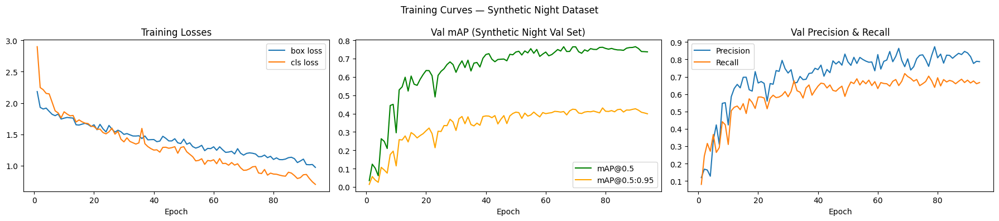

Best mAP@0.5 (synth val): 0.7648 at epoch 90


In [36]:
# Plot training curves
csv_path = PROJECT_DIR / RUN_NAME / 'results.csv'
if csv_path.exists():
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    axes[0].plot(df['epoch'], df['train/box_loss'], label='box loss')
    axes[0].plot(df['epoch'], df['train/cls_loss'], label='cls loss')
    axes[0].set_title('Training Losses'); axes[0].legend(); axes[0].set_xlabel('Epoch')
    axes[1].plot(df['epoch'], df['metrics/mAP50(B)'], color='green', label='mAP@0.5')
    axes[1].plot(df['epoch'], df['metrics/mAP50-95(B)'], color='orange', label='mAP@0.5:0.95')
    axes[1].set_title('Val mAP (Synthetic Night Val Set)')
    axes[1].legend(); axes[1].set_xlabel('Epoch')
    axes[2].plot(df['epoch'], df['metrics/precision(B)'], label='Precision')
    axes[2].plot(df['epoch'], df['metrics/recall(B)'], label='Recall')
    axes[2].set_title('Val Precision & Recall')
    axes[2].legend(); axes[2].set_xlabel('Epoch')
    plt.suptitle('Training Curves — Synthetic Night Dataset', fontsize=12)
    plt.tight_layout(); savefig('05_training_curves.png'); plt.show()
    print(f"Best mAP@0.5 (synth val): {df['metrics/mAP50(B)'].max():.4f} at epoch {df['metrics/mAP50(B)'].idxmax()+1}")

## Step 9 — Evaluate on Real Night Test Set

This is the **key result**: how well does the model trained on synthetic night images generalise to **real** night-time pothole images it has never seen?

In [37]:
# Write a data.yaml that points val/test to the real night images
real_yaml_path = WORK / 'real_night_eval.yaml'
with open(real_yaml_path, 'w') as f:
    yaml.dump({
        'path': str(WORK),
        'train': str(OUT_DIR / 'train' / 'images'),   # not used here
        'val':   str(REAL_VAL_DIR  / 'images'),
        'test':  str(REAL_TEST_DIR / 'images'),
        'nc': 1,
        'names': {0: 'pothole'}
    }, f, sort_keys=False)

best_model = YOLO(str(BEST_PT))

print('=== Evaluation on REAL NIGHT VAL set ===')
val_results = best_model.val(
    data=str(real_yaml_path),
    split='val',
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    conf=0.001,
    iou=0.6,
    device=DEVICE,
    verbose=True,
)
print(f'Real Night VAL  mAP@0.5     : {val_results.box.map50:.4f}')
print(f'Real Night VAL  mAP@0.5:0.95: {val_results.box.map:.4f}')
print(f'Real Night VAL  Precision   : {val_results.box.mp:.4f}')
print(f'Real Night VAL  Recall      : {val_results.box.mr:.4f}')

print('\n=== Evaluation on REAL NIGHT TEST set ===')
test_results = best_model.val(
    data=str(real_yaml_path),
    split='test',
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    conf=0.001,
    iou=0.6,
    device=DEVICE,
    verbose=True,
)
print(f'Real Night TEST mAP@0.5     : {test_results.box.map50:.4f}')
print(f'Real Night TEST mAP@0.5:0.95: {test_results.box.map:.4f}')
print(f'Real Night TEST Precision   : {test_results.box.mp:.4f}')
print(f'Real Night TEST Recall      : {test_results.box.mr:.4f}')

=== Evaluation on REAL NIGHT VAL set ===
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11m summary (fused): 125 layers, 20,030,803 parameters, 0 gradients, 67.8 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 27.9±26.5 MB/s, size: 83.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/working/real_val/labels... 217 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 217/217 559.6it/s 0.4s
val: New cache created: /content/working/real_val/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 14/14 1.9it/s 7.3s
                   all        217        492       0.17      0.118     0.0606     0.0203
Speed: 1.3ms preprocess, 27.6ms inference, 0.0ms loss, 0.8ms postprocess per image
Results saved to /content/runs/detect/val
Real Night VAL  mAP@0

In [38]:
# Summary table
rows = [
    {'Eval Set': 'Synthetic Night Val (own domain)',
     'mAP@0.5': f"{val_results.box.map50:.4f}",
     'mAP@0.5:0.95': f"{val_results.box.map:.4f}",
     'Precision': f"{val_results.box.mp:.4f}",
     'Recall': f"{val_results.box.mr:.4f}"},
    {'Eval Set': '>>> Real Night TEST (cross-domain) <<<',
     'mAP@0.5': f"{test_results.box.map50:.4f}",
     'mAP@0.5:0.95': f"{test_results.box.map:.4f}",
     'Precision': f"{test_results.box.mp:.4f}",
     'Recall': f"{test_results.box.mr:.4f}"},
]
df_summary = pd.DataFrame(rows).set_index('Eval Set')
print('\n' + '='*60)
print('RESULTS SUMMARY')
print('='*60)
display(df_summary)

# Generalisation gap
gap = val_results.box.map50 - test_results.box.map50
print(f'\nGeneralisation gap (synth val mAP50 − real test mAP50): {gap:+.4f}')
if gap < 0.10:
    print('✅ Small gap — synthetic training transfers well to real night!')
elif gap < 0.20:
    print('⚠️  Moderate gap — model partially generalises to real night.')
else:
    print('❌ Large gap — domain shift is significant; consider mixed training.')


RESULTS SUMMARY


,mAP@0.5,mAP@0.5:0.95,Precision,Recall
Eval Set,,,,
Synthetic Night Val (own domain),0.0606,0.0203,0.1698,0.1179
>>> Real Night TEST (cross-domain) <<<,0.0676,0.0223,0.2367,0.1180



Generalisation gap (synth val mAP50 − real test mAP50): -0.0070
✅ Small gap — synthetic training transfers well to real night!


## Step 10 — Qualitative Results & Download

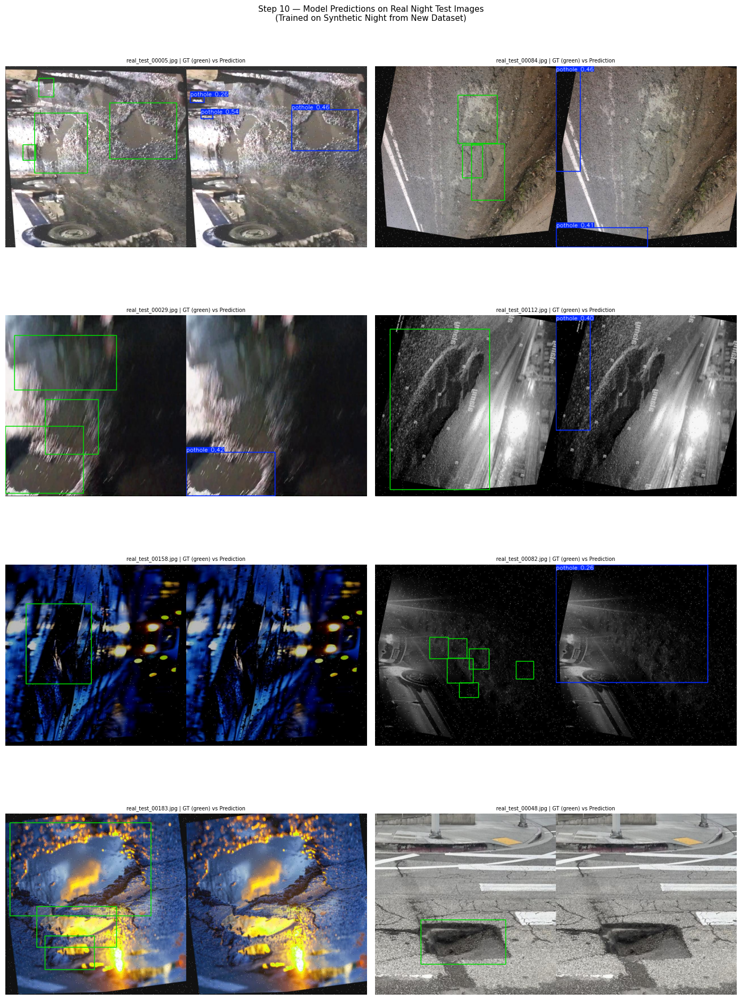

In [39]:
# Show predictions on real night test images
real_test_imgs = list((REAL_TEST_DIR / 'images').iterdir())
show_imgs = random.Random(42).sample(real_test_imgs, min(8, len(real_test_imgs)))

fig, axes = plt.subplots(4, 2, figsize=(14, 20))
for ax, img_path in zip(axes.flat, show_imgs):
    img_bgr = cv2.imread(str(img_path))
    # Ground truth
    lab = read_yolo_labels(label_path_for(img_path))
    img_gt = draw_boxes(img_bgr.copy(), lab, color=(0, 220, 0))   # green = GT
    # Prediction
    pred = best_model.predict(str(img_path), imgsz=IMG_SIZE,
                              conf=0.25, iou=0.45,
                              device=DEVICE, verbose=False)[0]
    img_pred = pred.plot(line_width=2)                             # Ultralytics overlay
    # Side-by-side within one axis
    combined = np.concatenate([img_gt, img_pred], axis=1)
    ax.imshow(cv2.cvtColor(combined, cv2.COLOR_BGR2RGB))
    ax.set_title(f'{img_path.name} | GT (green) vs Prediction', fontsize=7)
    ax.axis('off')
plt.suptitle('Step 10 — Model Predictions on Real Night Test Images\n'
             '(Trained on Synthetic Night from New Dataset)',
             fontsize=11)
plt.tight_layout(); savefig('06_qualitative_real_night.png'); plt.show()

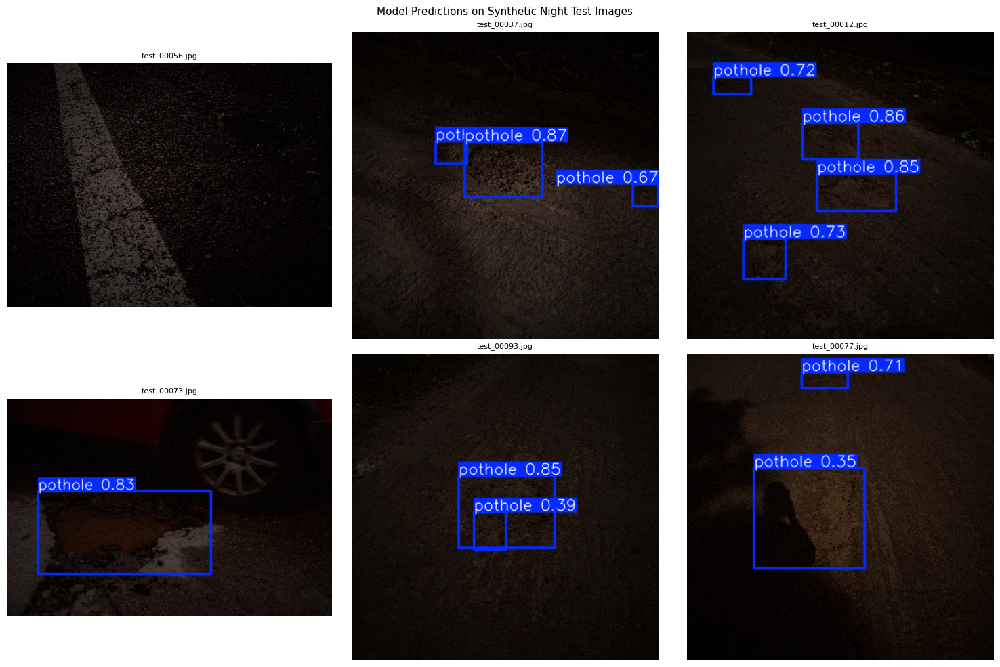

In [40]:
# Also show predictions on the synthetic night test images
synth_test_imgs = list((OUT_DIR / 'test' / 'images').iterdir())
show_synth = random.Random(SEED).sample(synth_test_imgs, min(6, len(synth_test_imgs)))
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, img_path in zip(axes.flat, show_synth):
    pred = best_model.predict(str(img_path), imgsz=IMG_SIZE,
                              conf=0.25, iou=0.45,
                              device=DEVICE, verbose=False)[0]
    ax.imshow(cv2.cvtColor(pred.plot(line_width=2), cv2.COLOR_BGR2RGB))
    ax.set_title(img_path.name, fontsize=8); ax.axis('off')
plt.suptitle('Model Predictions on Synthetic Night Test Images', fontsize=11)
plt.tight_layout(); savefig('07_qualitative_synth_test.png'); plt.show()

In [41]:
# Save summary CSV and all figures to a zip
df_summary.to_csv(WORK / 'results_summary.csv')

ZIP_PATH = WORK / 'new_dataset_night_results.zip'
ZIP_PATH.unlink(missing_ok=True)
files_to_zip = (
    list(FIGS_DIR.glob('*.png')) +
    [WORK / 'results_summary.csv', BEST_PT,
     PROJECT_DIR / RUN_NAME / 'results.csv',
     data_yaml_path, real_yaml_path]
)
with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in files_to_zip:
        p = Path(p)
        if p.exists():
            z.write(p, p.relative_to(WORK))

print(f'ZIP: {ZIP_PATH}  ({ZIP_PATH.stat().st_size/1e6:.1f} MB)')
display(FileLink('new_dataset_night_results.zip',
                 result_html_prefix='📦 Download all results: '))

print('\n=== FINAL SUMMARY ===')
print(f'  Model          : {MODEL_WEIGHTS}')
print(f'  Training data  : Synthetic night (from {len(all_items)} New Dataset images)')
print(f'  Train images   : {n_tr} | Val: {n_va} | Test: {n_te}')
print(f'  Synth val  mAP@0.5: {val_results.box.map50:.4f}')
print(f'  REAL night mAP@0.5: {test_results.box.map50:.4f}  ← key result')
print(f'  Best checkpoint: {BEST_PT}')

ZIP: /content/working/new_dataset_night_results.zip  (58.6 MB)


/content/new_dataset_night_results.zip


=== FINAL SUMMARY ===
  Model          : yolo11m.pt
  Training data  : Synthetic night (from 665 New Dataset images)
  Train images   : 465 | Val: 100 | Test: 100
  Synth val  mAP@0.5: 0.0606
  REAL night mAP@0.5: 0.0676  ← key result
  Best checkpoint: /content/working/runs/yolo11m_synthetic_night/weights/best.pt
